# ATLAS 2050 : analyse exploratoire du gold, Gironde (33), DVF 2024

Lecture directe de `data/gold/*.parquet` avec DuckDB, graphiques matplotlib. Tables : `fact_transactions`, `dim_iris`, `dim_commune`, `fact_risques_commune`, `agg_hex`.

**Confidentialité (ADR 0005).** Ce notebook n'affiche aucune vente individuelle : ni adresse, ni identifiant de mutation ou de parcelle, ni tableau de lignes. Il ne montre que des agrégats (effectifs, médianes, quartiles) et des distributions. Le nuage de la section 4 est tracé par IRIS (médiane des ventes de l'IRIS, au moins 5 ventes), pas par vente.

**Lecture des conclusions.** Chaque chiffre cité dans une conclusion est calculé dans la cellule qui la produit. Les corrélations sont des associations, pas des causes.

In [1]:
from pathlib import Path
import duckdb
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})

# Racine du dépôt : le notebook peut être lancé depuis docs/analysis ou depuis la racine.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "gold").is_dir())
GOLD = ROOT / "data" / "gold"

con = duckdb.connect()
for t in ["fact_transactions", "dim_iris", "dim_commune", "fact_risques_commune", "agg_hex"]:
    con.execute(f"CREATE VIEW {t} AS SELECT * FROM read_parquet('{(GOLD / (t + '.parquet')).as_posix()}')")

def rows(sql):
    return con.sql(sql).fetchall()

def fr(x, d=0):
    # nombre au format français : espace insécable fine en milliers, virgule décimale
    s = f"{x:,.{d}f}".replace(",", "\u202f").replace(".", ",")
    return s

def conclure(texte):
    display(Markdown("**Conclusion.** " + texte))

def rang(a):
    # rang moyen (gestion des ex aequo), sans scipy
    _, inv, cnt = np.unique(a, return_inverse=True, return_counts=True)
    fin = np.cumsum(cnt)
    return ((fin - cnt + 1 + fin) / 2.0)[inv]

def spearman(x, y):
    x = np.asarray(x, float); y = np.asarray(y, float)
    m = ~(np.isnan(x) | np.isnan(y))
    if m.sum() < 3 or np.ptp(x[m]) == 0 or np.ptp(y[m]) == 0:
        return float("nan"), int(m.sum())
    return float(np.corrcoef(rang(x[m]), rang(y[m]))[0, 1]), int(m.sum())

N, = rows("SELECT count(*) FROM fact_transactions")[0]
N_COM, = rows("SELECT count(DISTINCT code_commune) FROM fact_transactions")[0]
print(f"{fr(N)} ventes (maisons et appartements, 2024) dans {fr(N_COM)} communes de Gironde")

17 766 ventes (maisons et appartements, 2024) dans 499 communes de Gironde


## 1. Distribution du prix au m², maisons et appartements

`prix_m2` = valeur foncière / surface bâtie. Échelle logarithmique, car la distribution est asymétrique à droite.

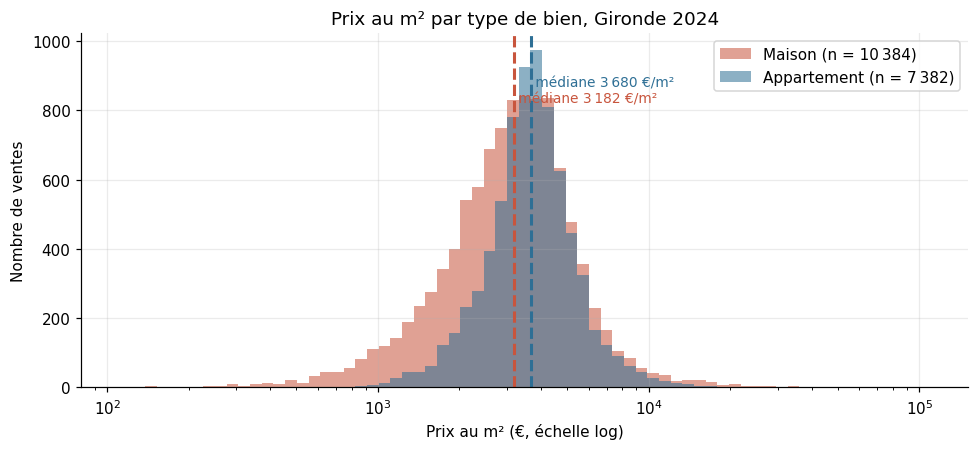

**Conclusion.** La médiane est de 3 182 €/m² pour les maisons (n = 10 384) et de 3 680 €/m² pour les appartements (n = 7 382), soit 15,7 % de plus pour les appartements ; la dispersion est plus large pour les maisons (90 % des ventes entre 1 050 et 6 989 €/m², contre 1 876 à 6 750 pour les appartements) et les valeurs extrêmes vont de 113 à 107 333 €/m², ce qui impose un filtrage des valeurs aberrantes avant tout modèle.

In [2]:
par_type = {t: np.array([r[0] for r in rows(f"SELECT prix_m2 FROM fact_transactions WHERE type_local='{t}'")])
            for t in ["Maison", "Appartement"]}
stats = {t: dict(n=len(v), med=float(np.median(v)), q1=float(np.quantile(v, .25)), q3=float(np.quantile(v, .75)),
                 p5=float(np.quantile(v, .05)), p95=float(np.quantile(v, .95)), mn=float(v.min()), mx=float(v.max()))
         for t, v in par_type.items()}

allv = np.concatenate(list(par_type.values()))
bins = np.logspace(np.log10(allv.min()), np.log10(allv.max()), 70)
couleurs = {"Maison": "#c8553d", "Appartement": "#2e6f95"}

fig, ax = plt.subplots(figsize=(9, 4.2))
for t, v in par_type.items():
    ax.hist(v, bins=bins, alpha=.55, color=couleurs[t], label=f"{t} (n = {fr(len(v))})")
    ax.axvline(stats[t]["med"], color=couleurs[t], lw=2, ls="--")
    ax.text(stats[t]["med"], ax.get_ylim()[1] * (.97 if t == "Maison" else .88),
            f" médiane {fr(stats[t]['med'])} €/m²", color=couleurs[t], fontsize=9, va="top")
ax.set_xscale("log")
ax.set_xlabel("Prix au m² (€, échelle log)")
ax.set_ylabel("Nombre de ventes")
ax.set_title("Prix au m² par type de bien, Gironde 2024")
ax.legend()
plt.tight_layout(); plt.show()

m, a = stats["Maison"], stats["Appartement"]
conclure(
    f"La médiane est de {fr(m['med'])} €/m² pour les maisons (n = {fr(m['n'])}) et de {fr(a['med'])} €/m² pour les appartements "
    f"(n = {fr(a['n'])}), soit {fr((a['med']/m['med']-1)*100, 1)} % de plus pour les appartements ; "
    f"la dispersion est plus large pour les maisons (90 % des ventes entre {fr(m['p5'])} et {fr(m['p95'])} €/m², "
    f"contre {fr(a['p5'])} à {fr(a['p95'])} pour les appartements) et les valeurs extrêmes vont de {fr(m['mn'])} à {fr(m['mx'])} €/m², "
    f"ce qui impose un filtrage des valeurs aberrantes avant tout modèle."
)

## 2. Prix au m² selon la classe DPE (A à G), ventes appariées seulement

Seules les ventes dont le DPE a pu être rattaché (`dpe_appariement = 'apparie'`) figurent ici. Le rattachement passe par DVF, la BAN puis le DPE connu à la date de vente.

**Biais de sélection, à lire avant le graphique.** Seule une petite minorité des ventes est appariée, et ce sous-ensemble n'est pas représentatif : il est composé presque exclusivement de maisons, alors que les appartements (immeubles à plusieurs DPE, adresses absentes de la table cadastrale de la BAN) sont presque tous écartés. Toute lecture « effet du DPE sur le prix » sur ce sous-ensemble est donc confondue avec le type de bien, la commune et l'ancienneté.

In [3]:
statut = rows('''SELECT dpe_appariement, count(*) FROM fact_transactions GROUP BY 1 ORDER BY 2 DESC''')
n_app = dict(statut).get("apparie", 0)
part_app = n_app / N * 100
par_type_app = dict(rows("SELECT type_local, count(*) FROM fact_transactions WHERE dpe_appariement='apparie' GROUP BY 1"))
par_type_all = dict(rows("SELECT type_local, count(*) FROM fact_transactions GROUP BY 1"))
part_maison_app = par_type_app.get("Maison", 0) / n_app * 100
part_maison_all = par_type_all["Maison"] / N * 100
tx_app = {t: par_type_app.get(t, 0) / par_type_all[t] * 100 for t in par_type_all}
print("Statut d'appariement (effectifs agrégés) :")
for s, c in statut:
    print(f"  {s:<15} {fr(c):>8}  {fr(c / N * 100, 1):>5} %")
print(f"Part de maisons : {fr(part_maison_app, 1)} % des ventes appariées contre {fr(part_maison_all, 1)} % de l'ensemble")
print("Taux d'appariement par type :", {t: fr(v, 1) + ' %' for t, v in tx_app.items()})

Statut d'appariement (effectifs agrégés) :
  sans_adresse      13 639   76,8 %
  apparie            1 905   10,7 %
  sans_dpe           1 707    9,6 %
  plusieurs_dpe        446    2,5 %
  type_different        69    0,4 %
Part de maisons : 97,3 % des ventes appariées contre 58,4 % de l'ensemble
Taux d'appariement par type : {'Appartement': '0,7 %', 'Maison': '17,9 %'}


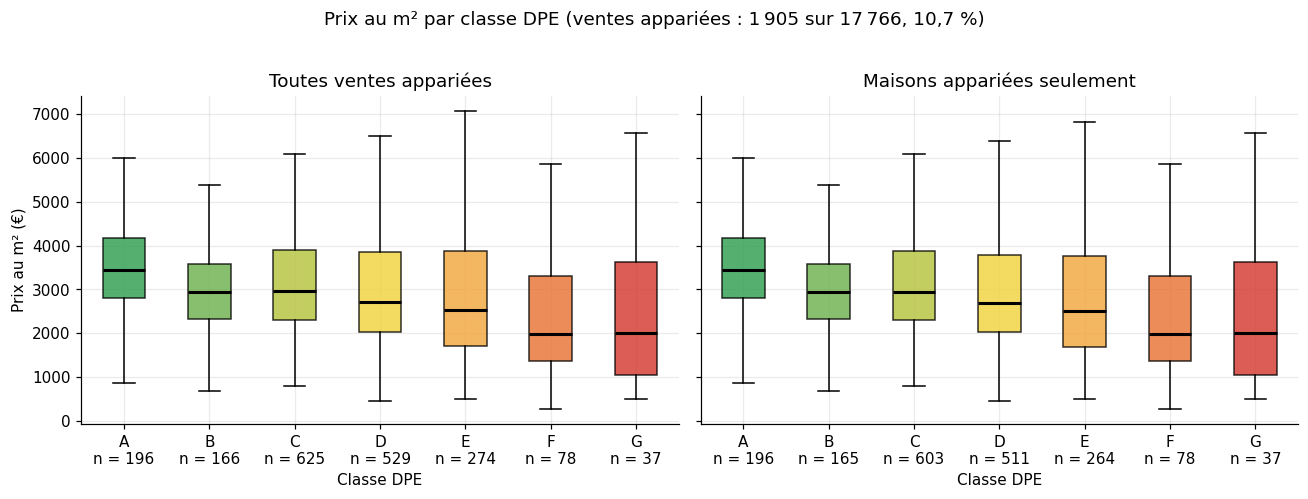

**Conclusion.** Seules 1 905 ventes sur 17 766 (10,7 %) sont appariées à un DPE et 97,3 % d'entre elles sont des maisons (contre 58,4 % de l'ensemble), de sorte que ce sous-ensemble ne représente ni les appartements ni la Gironde entière ; sur ce sous-ensemble, la médiane passe de 3 440 €/m² en classe A (n = 196) à 2 000 €/m² en classe G (n = 37), avec un Spearman classe/prix de -0,19 (maisons seules : -0,20), mais les classes F et G ne comptent que 78 et 37 ventes et l'écart ne peut pas être attribué au seul DPE.

In [4]:
CLASSES = list("ABCDEFG")
def par_classe(filtre=""):
    d = {c: [] for c in CLASSES}
    for c, p in rows(f"SELECT dpe_etiquette, prix_m2 FROM fact_transactions WHERE dpe_appariement='apparie' AND dpe_etiquette IN ('A','B','C','D','E','F','G') {filtre}"):
        d[c].append(p)
    return {c: np.array(v) for c, v in d.items()}

tout = par_classe()
maisons = par_classe("AND type_local='Maison'")
nuances = ["#2a9d4b", "#6bb04a", "#b5c23a", "#f0d23a", "#f2a53a", "#e8702f", "#d2352b"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
for ax, data, titre in [(axes[0], tout, "Toutes ventes appariées"), (axes[1], maisons, "Maisons appariées seulement")]:
    bp = ax.boxplot([data[c] for c in CLASSES], patch_artist=True, showfliers=False, medianprops=dict(color="black", lw=2))
    for patch, col in zip(bp["boxes"], nuances):
        patch.set_facecolor(col); patch.set_alpha(.8)
    ax.set_xticks(range(1, 8))
    ax.set_xticklabels([f"{c}\nn = {fr(len(data[c]))}" for c in CLASSES])
    ax.set_title(titre); ax.set_xlabel("Classe DPE")
axes[0].set_ylabel("Prix au m² (€)")
fig.suptitle(f"Prix au m² par classe DPE (ventes appariées : {fr(n_app)} sur {fr(N)}, {fr(part_app, 1)} %)", y=1.02)
plt.tight_layout(); plt.show()

med = {c: float(np.median(tout[c])) for c in CLASSES}
medm = {c: float(np.median(maisons[c])) for c in CLASSES}
n_cl = {c: len(tout[c]) for c in CLASSES}
rho_dpe, n_rho = spearman(np.concatenate([[CLASSES.index(c)] * len(tout[c]) for c in CLASSES]),
                          np.concatenate([tout[c] for c in CLASSES]))
rho_dpe_m, n_rho_m = spearman(np.concatenate([[CLASSES.index(c)] * len(maisons[c]) for c in CLASSES]),
                              np.concatenate([maisons[c] for c in CLASSES]))
conclure(
    f"Seules {fr(n_app)} ventes sur {fr(N)} ({fr(part_app, 1)} %) sont appariées à un DPE et {fr(part_maison_app, 1)} % d'entre elles sont des maisons "
    f"(contre {fr(part_maison_all, 1)} % de l'ensemble), de sorte que ce sous-ensemble ne représente ni les appartements ni la Gironde entière ; "
    f"sur ce sous-ensemble, la médiane passe de {fr(med['A'])} €/m² en classe A (n = {fr(n_cl['A'])}) à {fr(med['G'])} €/m² en classe G (n = {fr(n_cl['G'])}), "
    f"avec un Spearman classe/prix de {fr(rho_dpe, 2)} (maisons seules : {fr(rho_dpe_m, 2)}), mais les classes F et G ne comptent que {fr(n_cl['F'])} et {fr(n_cl['G'])} ventes "
    f"et l'écart ne peut pas être attribué au seul DPE."
)

## 3. Prix au m² et exposition aux risques de la commune

Jointure `fact_transactions` avec `fact_risques_commune` sur le code INSEE de la commune. Les boîtes sont pondérées par vente (une commune qui vend beaucoup pèse plus). `n_catnat` = nombre d'arrêtés Cat-Nat distincts sur la commune, tous millésimes ; `ppri` = commune avec un PPRN inondation ou littoral ; `in_tri` = commune en Territoire à Risque d'Inondation important.

Communes avec risques : 534 ; arrêtés Cat-Nat par commune : min 3, médiane 9.0, max 42


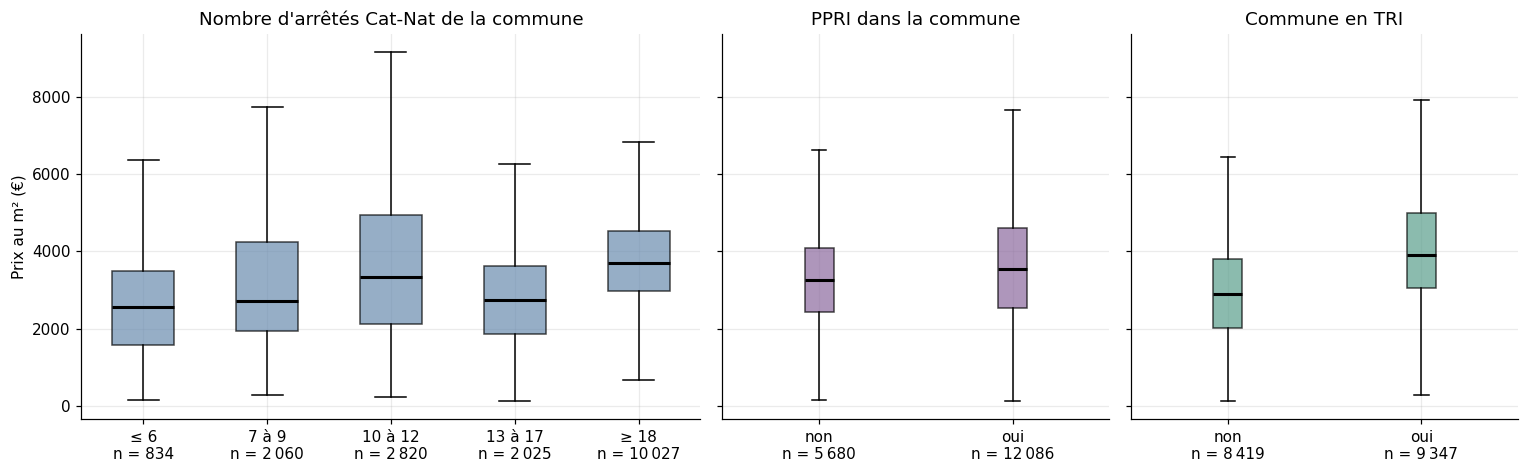

Médianes €/m² selon TRI, par type (agrégats) : {'Maison': (2707, 3938), 'Appartement': (3333, 3868)} (non TRI, TRI)
Médianes €/m² selon PPRI, par type (agrégats) : {'Maison': (3141, 3204), 'Appartement': (3451, 3784)} (non PPRI, PPRI)
Part d'appartements : 55,0 % des ventes en TRI contre 26,6 % hors TRI


In [5]:
base_risque = rows('''
    SELECT t.prix_m2, r.n_catnat, r.ppri, r.in_tri, t.type_local
    FROM fact_transactions t JOIN fact_risques_commune r ON r.code_insee = t.code_commune''')
prix = np.array([r[0] for r in base_risque])
ncat = np.array([r[1] for r in base_risque], float)
ppri = np.array([bool(r[2]) for r in base_risque])
tri = np.array([bool(r[3]) for r in base_risque])
typ = np.array([r[4] for r in base_risque])
assert len(prix) == N  # toutes les ventes ont une ligne de risques

n_com_risque, cmin, cmax, cmed = rows("SELECT count(*), min(n_catnat), max(n_catnat), median(n_catnat) FROM fact_risques_commune")[0]
print(f"Communes avec risques : {n_com_risque} ; arrêtés Cat-Nat par commune : min {cmin}, médiane {cmed}, max {cmax}")

bords = [(0, 6), (7, 9), (10, 12), (13, 17), (18, 99)]
etiq = ["≤ 6", "7 à 9", "10 à 12", "13 à 17", "≥ 18"]
groupes_cat = [prix[(ncat >= lo) & (ncat <= hi)] for lo, hi in bords]
communes_par_bin = [rows(f"SELECT count(*) FROM fact_risques_commune WHERE n_catnat BETWEEN {lo} AND {hi}")[0][0] for lo, hi in bords]

fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), sharey=True, gridspec_kw={"width_ratios": [1.6, 1, 1]})
def boite(ax, groupes, labels, titre, couleur):
    bp = ax.boxplot(groupes, patch_artist=True, showfliers=False, medianprops=dict(color="black", lw=2))
    for p in bp["boxes"]:
        p.set_facecolor(couleur); p.set_alpha(.7)
    ax.set_xticks(range(1, len(groupes) + 1))
    ax.set_xticklabels([f"{l}\nn = {fr(len(g))}" for l, g in zip(labels, groupes)])
    ax.set_title(titre)
boite(axes[0], groupes_cat, etiq, "Nombre d'arrêtés Cat-Nat de la commune", "#6a8caf")
boite(axes[1], [prix[~ppri], prix[ppri]], ["non", "oui"], "PPRI dans la commune", "#8c6a9e")
boite(axes[2], [prix[~tri], prix[tri]], ["non", "oui"], "Commune en TRI", "#5a9e8c")
axes[0].set_ylabel("Prix au m² (€)")
plt.tight_layout(); plt.show()

rho_cat, _ = spearman(ncat, prix)
rho_cat_m, _ = spearman(ncat[typ == "Maison"], prix[typ == "Maison"])
rho_cat_a, _ = spearman(ncat[typ == "Appartement"], prix[typ == "Appartement"])
med_ppri = (np.median(prix[~ppri]), np.median(prix[ppri])); n_ppri = ((~ppri).sum(), ppri.sum())
med_tri = (np.median(prix[~tri]), np.median(prix[tri])); n_tri = ((~tri).sum(), tri.sum())
part_app_tri = (typ[tri] == "Appartement").mean() * 100
part_app_non_tri = (typ[~tri] == "Appartement").mean() * 100
# médianes par type pour contrôler l'effet de composition
def med_t(mask, t): return float(np.median(prix[mask & (typ == t)]))
print("Médianes €/m² selon TRI, par type (agrégats) :",
      {t: (round(med_t(~tri, t)), round(med_t(tri, t))) for t in ["Maison", "Appartement"]}, "(non TRI, TRI)")
print("Médianes €/m² selon PPRI, par type (agrégats) :",
      {t: (round(med_t(~ppri, t)), round(med_t(ppri, t))) for t in ["Maison", "Appartement"]}, "(non PPRI, PPRI)")
print(f"Part d'appartements : {fr(part_app_tri, 1)} % des ventes en TRI contre {fr(part_app_non_tri, 1)} % hors TRI")

In [6]:
mt = {t: (med_t(~tri, t), med_t(tri, t)) for t in ["Maison", "Appartement"]}
conclure(
    f"Les ventes en commune TRI ont une médiane de {fr(med_tri[1])} €/m² (n = {fr(n_tri[1])}) contre {fr(med_tri[0])} hors TRI (n = {fr(n_tri[0])}), "
    f"et celles en commune PPRI {fr(med_ppri[1])} contre {fr(med_ppri[0])} (n = {fr(n_ppri[1])} et {fr(n_ppri[0])}) : "
    f"les communes à risque sont plus chères, ce qui reflète leur caractère urbain ({fr(part_app_tri, 1)} % d'appartements en TRI contre {fr(part_app_non_tri, 1)} % hors TRI) "
    f"et leur localisation, pas un prix du risque, puisque l'écart persiste à type égal (maisons {fr(mt['Maison'][1])} contre {fr(mt['Maison'][0])} €/m²) ; "
    f"le Spearman entre nombre d'arrêtés Cat-Nat ({cmin} à {cmax} par commune) et prix n'est que de {fr(rho_cat, 2)} (maisons {fr(rho_cat_m, 2)}, appartements {fr(rho_cat_a, 2)}), "
    f"une association modérée qui ne permet aucune lecture causale."
)

**Conclusion.** Les ventes en commune TRI ont une médiane de 3 892 €/m² (n = 9 347) contre 2 906 hors TRI (n = 8 419), et celles en commune PPRI 3 537 contre 3 261 (n = 12 086 et 5 680) : les communes à risque sont plus chères, ce qui reflète leur caractère urbain (55,0 % d'appartements en TRI contre 26,6 % hors TRI) et leur localisation, pas un prix du risque, puisque l'écart persiste à type égal (maisons 3 938 contre 2 707 €/m²) ; le Spearman entre nombre d'arrêtés Cat-Nat (3 à 42 par commune) et prix n'est que de 0,32 (maisons 0,35, appartements 0,21), une association modérée qui ne permet aucune lecture causale.

## 4. Prix au m² et revenu médian de l'IRIS (Filosofi)

Le revenu médian (`dim_iris.revenu_median`) n'existe que pour une partie des IRIS (communes de plus de 5 000 habitants, IRIS diffusés). Le nuage est tracé par IRIS pour ne pas exposer de vente individuelle : un point = un IRIS avec au moins 5 ventes, ordonnée = médiane du prix au m² de ses ventes, taille proportionnelle au nombre de ventes. Le coefficient de Spearman est calculé sur les deux niveaux (IRIS, puis ventes).

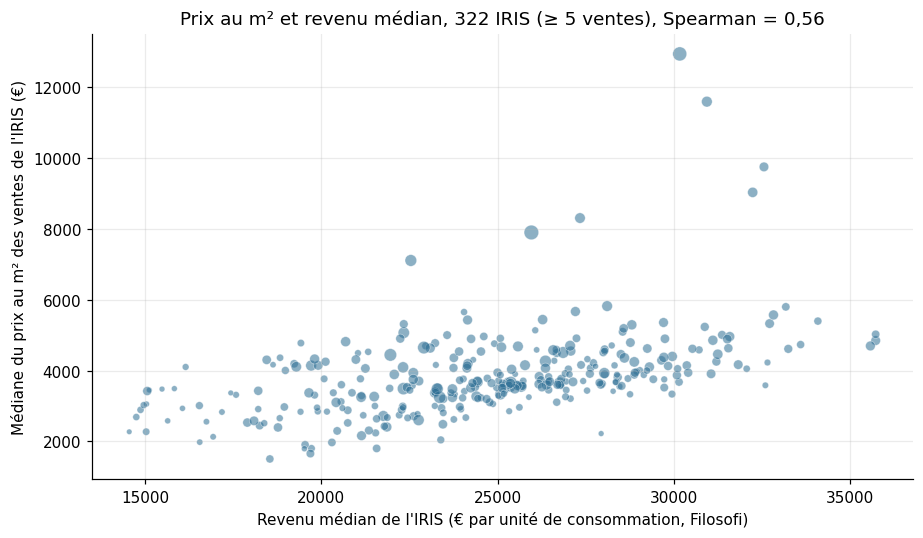

**Conclusion.** Sur les 11 622 ventes situées dans un IRIS doté d'un revenu (65,4 % des 17 766 ventes ; 323 IRIS sur 837), le Spearman entre revenu médian de l'IRIS et prix au m² est de 0,38 (maisons 0,46, appartements 0,31) et de 0,56 au niveau des 322 IRIS d'au moins 5 ventes, ce qui fait du revenu un prédicteur d'intensité modérée, et disponible pour moins de deux ventes sur trois seulement.

In [7]:
cov = rows('''SELECT count(*) FILTER (WHERE i.revenu_median IS NOT NULL), count(*) FROM fact_transactions t LEFT JOIN dim_iris i USING (code_iris)''')[0]
n_rev, n_tot = cov
iris = rows('''
    SELECT i.revenu_median, median(t.prix_m2), count(*), any_value(t.type_local = 'Maison')
    FROM fact_transactions t JOIN dim_iris i USING (code_iris)
    WHERE i.revenu_median IS NOT NULL
    GROUP BY t.code_iris, i.revenu_median HAVING count(*) >= 5''')
x = np.array([r[0] for r in iris]); y = np.array([r[1] for r in iris]); w = np.array([r[2] for r in iris])
n_iris_rev = rows("SELECT count(*) FROM dim_iris WHERE revenu_median IS NOT NULL")[0][0]
n_iris_tot = rows("SELECT count(*) FROM dim_iris")[0][0]

vente = rows('''SELECT i.revenu_median, t.prix_m2, t.type_local FROM fact_transactions t JOIN dim_iris i USING (code_iris) WHERE i.revenu_median IS NOT NULL''')
vx = np.array([r[0] for r in vente]); vy = np.array([r[1] for r in vente]); vt = np.array([r[2] for r in vente])
rho_v, n_v = spearman(vx, vy)
rho_i, n_i = spearman(x, y)
rho_vm, _ = spearman(vx[vt == "Maison"], vy[vt == "Maison"])
rho_va, _ = spearman(vx[vt == "Appartement"], vy[vt == "Appartement"])

fig, ax = plt.subplots(figsize=(8.5, 5))
sc = ax.scatter(x, y, s=10 + w * 0.6, alpha=.55, color="#2e6f95", edgecolor="white", linewidth=.4)
k, b = np.polyfit(rang(x), rang(y), 1)
ax.set_xlabel("Revenu médian de l'IRIS (€ par unité de consommation, Filosofi)")
ax.set_ylabel("Médiane du prix au m² des ventes de l'IRIS (€)")
ax.set_title(f"Prix au m² et revenu médian, {n_i} IRIS (≥ 5 ventes), Spearman = {fr(rho_i, 2)}")
plt.tight_layout(); plt.show()

conclure(
    f"Sur les {fr(n_v)} ventes situées dans un IRIS doté d'un revenu ({fr(n_v / n_tot * 100, 1)} % des {fr(n_tot)} ventes ; {n_iris_rev} IRIS sur {n_iris_tot}), "
    f"le Spearman entre revenu médian de l'IRIS et prix au m² est de {fr(rho_v, 2)} (maisons {fr(rho_vm, 2)}, appartements {fr(rho_va, 2)}) "
    f"et de {fr(rho_i, 2)} au niveau des {n_i} IRIS d'au moins 5 ventes, ce qui fait du revenu un prédicteur d'intensité modérée, et disponible pour moins de deux ventes sur trois seulement."
)

## 5. Matrice de corrélation des variables candidates pour le sprint 3

Corrélation de rang (Spearman), calculée par paires complètes : chaque case utilise les ventes où les deux variables sont renseignées (l'effectif varie donc d'une case à l'autre). `surface_terrain` n'existe que pour les maisons ; `dpe_classe` (A=1 à G=7) que pour les ventes appariées ; les variables Filosofi pour les IRIS dotés d'un revenu. Les booléens `ppri` et `in_tri` sont codés 0/1.

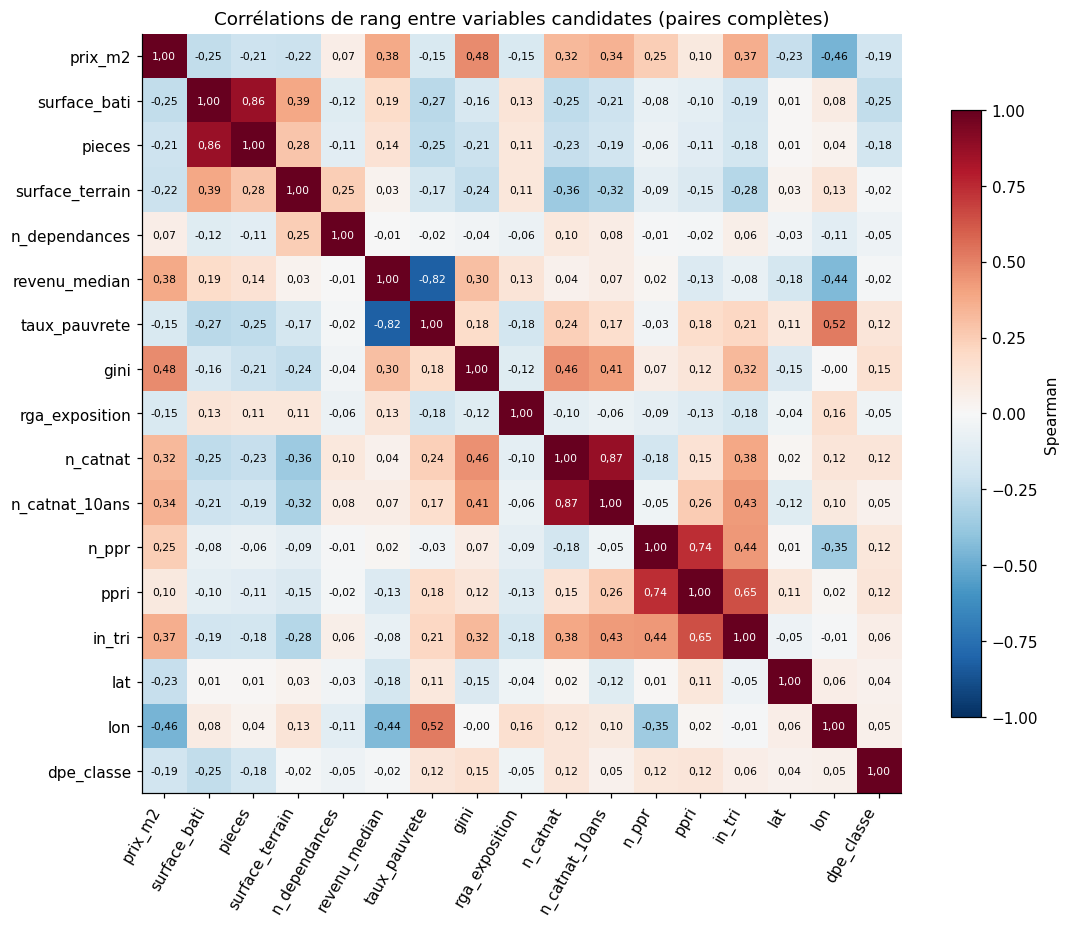

Valeurs renseignées par variable (sur 17 766 ventes) :
  prix_m2           17 766  100,0 %
  surface_bati      17 766  100,0 %
  pieces            17 766  100,0 %
  surface_terrain   10 384   58,4 %
  n_dependances     17 766  100,0 %
  revenu_median     11 622   65,4 %
  taux_pauvrete     11 622   65,4 %
  gini              11 622   65,4 %
  rga_exposition    15 621   87,9 %
  n_catnat          17 766  100,0 %
  n_catnat_10ans    17 766  100,0 %
  n_ppr             17 766  100,0 %
  ppri              17 766  100,0 %
  in_tri            17 766  100,0 %
  lat               17 766  100,0 %
  lon               17 766  100,0 %
  dpe_classe         1 905   10,7 %


In [8]:
sql = '''
SELECT t.prix_m2, t.surface_bati, t.pieces, t.surface_terrain, t.n_dependances,
       i.revenu_median, i.taux_pauvrete, i.gini, i.rga_code_exposition,
       r.n_catnat, r.n_catnat_10ans, r.n_ppr, r.ppri::INT, r.in_tri::INT,
       t.lat, t.lon,
       CASE WHEN t.dpe_appariement='apparie' THEN list_position(['A','B','C','D','E','F','G'], t.dpe_etiquette) END
FROM fact_transactions t
LEFT JOIN dim_iris i USING (code_iris)
LEFT JOIN fact_risques_commune r ON r.code_insee = t.code_commune'''
noms = ["prix_m2", "surface_bati", "pieces", "surface_terrain", "n_dependances", "revenu_median", "taux_pauvrete", "gini",
        "rga_exposition", "n_catnat", "n_catnat_10ans", "n_ppr", "ppri", "in_tri", "lat", "lon", "dpe_classe"]
X = np.array([[np.nan if v is None else float(v) for v in r] for r in rows(sql)])
k = len(noms)
C = np.full((k, k), np.nan); NN = np.zeros((k, k), int)
for a in range(k):
    for b in range(k):
        C[a, b], NN[a, b] = spearman(X[:, a], X[:, b])
renseigne = {n: int((~np.isnan(X[:, j])).sum()) for j, n in enumerate(noms)}

fig, ax = plt.subplots(figsize=(10.5, 8.5))
im = ax.imshow(C, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(k)); ax.set_xticklabels(noms, rotation=60, ha="right")
ax.set_yticks(range(k)); ax.set_yticklabels(noms)
for a in range(k):
    for b in range(k):
        if not np.isnan(C[a, b]):
            ax.text(b, a, f"{C[a, b]:.2f}".replace(".", ","), ha="center", va="center", fontsize=7,
                    color="white" if abs(C[a, b]) > .6 else "black")
ax.grid(False)
fig.colorbar(im, shrink=.8, label="Spearman")
ax.set_title("Corrélations de rang entre variables candidates (paires complètes)")
plt.tight_layout(); plt.show()

print("Valeurs renseignées par variable (sur", fr(N), "ventes) :")
for n_, c_ in renseigne.items():
    print(f"  {n_:<16} {fr(c_):>7}  {fr(c_ / N * 100, 1):>5} %")

In [9]:
ip = noms.index("prix_m2")
cibles = sorted([(abs(C[ip, j]), noms[j], C[ip, j], NN[ip, j]) for j in range(k) if j != ip and not np.isnan(C[ip, j])], reverse=True)
fortes = sorted({(round(abs(C[a, b]), 2), noms[a], noms[b], round(C[a, b], 2)) for a in range(k) for b in range(a + 1, k)
                 if not np.isnan(C[a, b]) and abs(C[a, b]) >= .7 and "prix_m2" not in (noms[a], noms[b])}, reverse=True)
top3 = ", ".join(f"{n_} ({fr(r, 2)}, n = {fr(nn)})" for _, n_, r, nn in cibles[:3])
faibles = ", ".join(f"{n_} ({fr(r, 2)})" for _, n_, r, _ in cibles[-3:])
colin = " ; ".join(f"{a} / {b} ({fr(r, 2)})" for _, a, b, r in fortes[:4]) or "aucune paire au-dessus de 0,7"
conclure(
    f"Les variables les plus liées au prix au m² sont {top3}, et les moins liées {faibles} ; "
    f"entre variables explicatives, les paires fortement colinéaires (|ρ| ≥ 0,7) sont {colin}, "
    f"alors que `surface_terrain` n'est renseignée que pour les maisons ({fr(renseigne['surface_terrain'])} ventes) et `dpe_classe` pour {fr(renseigne['dpe_classe'])} ventes seulement."
)

**Conclusion.** Les variables les plus liées au prix au m² sont gini (0,48, n = 11 622), lon (-0,46, n = 17 766), revenu_median (0,38, n = 11 622), et les moins liées taux_pauvrete (-0,15), ppri (0,10), n_dependances (0,07) ; entre variables explicatives, les paires fortement colinéaires (|ρ| ≥ 0,7) sont n_catnat / n_catnat_10ans (0,87) ; surface_bati / pieces (0,86) ; revenu_median / taux_pauvrete (-0,82) ; n_ppr / ppri (0,74), alors que `surface_terrain` n'est renseignée que pour les maisons (10 384 ventes) et `dpe_classe` pour 1 905 ventes seulement.

## 6. Ce que ça implique pour le modèle (sprint 3)

In [10]:
n_an, = rows("SELECT count(DISTINCT annee) FROM fact_transactions")[0]
surf_ratio = rows("SELECT median(prix_m2) FILTER (WHERE type_local='Maison'), median(prix_m2) FILTER (WHERE type_local='Appartement') FROM fact_transactions")[0]
d_min, d_max = rows("SELECT min(date_mutation), max(date_mutation) FROM fact_transactions")[0]
rho_gini = C[ip, noms.index("gini")]; rho_lon = C[ip, noms.index("lon")]
display(Markdown(f"""
- **Cible et type de bien.** Modéliser `log(prix_m2)` (distribution asymétrique, section 1) et traiter le type de bien comme variable majeure, voire entraîner deux modèles : les médianes diffèrent ({fr(surf_ratio[0])} contre {fr(surf_ratio[1])} €/m²) et `surface_terrain` n'existe que pour les maisons ({fr(renseigne['surface_terrain'])} ventes). Il faut un filtre de valeurs aberrantes (prix de {fr(stats['Maison']['mn'])} à {fr(stats['Maison']['mx'])} €/m² chez les maisons) avant l'entraînement.
- **DPE : pas de variable directe.** Seules {fr(n_app)} ventes ({fr(part_app, 1)} %) ont une classe DPE, à {fr(part_maison_app, 1)} % des maisons. L'utiliser telle quelle biaiserait le modèle vers les maisons et réduirait l'échantillon. Le DPE sert à l'analyse des décotes (ADR 0004), pas de feature d'entraînement tant que l'appariement n'est pas amélioré (repli spatial sur la parcelle, voir le rapport de qualité du gold).
- **Revenu Filosofi : utile mais incomplet.** `revenu_median` est renseigné pour {fr(renseigne['revenu_median'] / N * 100, 1)} % des ventes ; `gini` est la variable la plus corrélée au prix ({fr(rho_gini, 2)}). Prévoir un indicateur de valeur manquante et une imputation à la commune, jamais une imputation par le prix.
- **Risques : à contrôler par la localisation.** L'écart de prix entre communes TRI ou PPRI et les autres vient de la composition urbaine (section 3) : un coefficient « risque » estimé sans variable de localisation fine (H3, IRIS) serait trompeur. Les facteurs de décote d'ADR 0004 doivent être estimés à localisation égale.
- **Colinéarité.** Garder une variable par famille : `n_catnat` ou `n_catnat_10ans`, `ppri` ou `n_ppr`, `surface_bati` ou `pieces`, `revenu_median` ou `taux_pauvrete`. Les arbres (LightGBM) la tolèrent, le Ridge de référence non.
- **Validation.** `lon` est l'une des variables les plus liées au prix ({fr(rho_lon, 2)}) : la géographie domine, donc validation par `GroupKFold` par commune (ADR 0003). Le gold ne contient que {n_an} année ({d_min} au {d_max}) : le test temporel 2024 de l'ADR 0003 exige d'ingérer 2021 à 2023.
"""))


- **Cible et type de bien.** Modéliser `log(prix_m2)` (distribution asymétrique, section 1) et traiter le type de bien comme variable majeure, voire entraîner deux modèles : les médianes diffèrent (3 182 contre 3 680 €/m²) et `surface_terrain` n'existe que pour les maisons (10 384 ventes). Il faut un filtre de valeurs aberrantes (prix de 113 à 107 333 €/m² chez les maisons) avant l'entraînement.
- **DPE : pas de variable directe.** Seules 1 905 ventes (10,7 %) ont une classe DPE, à 97,3 % des maisons. L'utiliser telle quelle biaiserait le modèle vers les maisons et réduirait l'échantillon. Le DPE sert à l'analyse des décotes (ADR 0004), pas de feature d'entraînement tant que l'appariement n'est pas amélioré (repli spatial sur la parcelle, voir le rapport de qualité du gold).
- **Revenu Filosofi : utile mais incomplet.** `revenu_median` est renseigné pour 65,4 % des ventes ; `gini` est la variable la plus corrélée au prix (0,48). Prévoir un indicateur de valeur manquante et une imputation à la commune, jamais une imputation par le prix.
- **Risques : à contrôler par la localisation.** L'écart de prix entre communes TRI ou PPRI et les autres vient de la composition urbaine (section 3) : un coefficient « risque » estimé sans variable de localisation fine (H3, IRIS) serait trompeur. Les facteurs de décote d'ADR 0004 doivent être estimés à localisation égale.
- **Colinéarité.** Garder une variable par famille : `n_catnat` ou `n_catnat_10ans`, `ppri` ou `n_ppr`, `surface_bati` ou `pieces`, `revenu_median` ou `taux_pauvrete`. Les arbres (LightGBM) la tolèrent, le Ridge de référence non.
- **Validation.** `lon` est l'une des variables les plus liées au prix (-0,46) : la géographie domine, donc validation par `GroupKFold` par commune (ADR 0003). Le gold ne contient que 1 année (2024-01-02 au 2024-12-31) : le test temporel 2024 de l'ADR 0003 exige d'ingérer 2021 à 2023.
